# **Infer `Cellmask` and `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***

In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

## **SANDBOX FOR: Improved cell/nuclei segmentation**
<ins>Goals:</ins> Improve cell mask segmentation by implementing a machine learning approach. For comparison, the original masks_C workflow (without nuclei is included first).

Current thought process:
1. Segment nuclei manually from the inverse of a composite image (based on MCZ/ZC updates) -- this is actually very similar or exactly the same as what is done in 1.1a/b (see [NEW_infer-nuc_from-inverse-cyto.ipynb](NEW_infer-nuc_from-inverse-cyto.ipynb) notebook)
2. Input the PM staining and the nuclei segmentation into CellPose
3. POSSIBLY: add a trainable option to improve cyto3 model for iAstrocytes and iNeurons

--------------


---------------------
----------
# **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [1]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles.membrane import *
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm

%load_ext autoreload
%autoreload 2

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [2]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
data_root_path = Path("/users/s/r/srhoads/MJFF_Cellpose-batch-testing")
in_data_path = data_root_path / "KK-1"

im_type = ".tiff"

out_data_path = in_data_path / "20261112_batch-test"

vis_path = in_data_path / "20261112_figure-files"

#### &#x1F3C3; **Run code; no user input required**

In [3]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

if not Path.exists(vis_path):
    Path.mkdir(vis_path)
    print(f"making {vis_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome.tiff
1,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
2,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img12_zstack_Unmixing_decon.ome.tiff
3,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img13_zstack_Unmixing_decon.ome.tiff
4,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img14_zstack_Unmixing_decon.ome.tiff
5,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img15_zstack_Unmixing_decon.ome.tiff
6,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img2_zstack_Unmixing_decon.ome.tiff
7,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img6_zstack_Unmixing_decon.ome.tiff
8,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img8_zstack_Unmixing_decon.ome.tiff
9,/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img9_zstack_Unmixing_decon.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [4]:
#### USER INPUT REQUIRED ###
test_img_n = 0

#### &#x1F3C3; **Run code; no user input required**

Attempted file (/users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome.tiff) load with reader: aicsimageio.readers.bfio_reader.OmeTiledTiffReader failed with error: No module named 'bfio'


Metadata information
File path: /users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome.tiff
File name: /users/s/r/srhoads/MJFF_Cellpose-batch-testing/KK-1/04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome.tiff
Channel 0 name: 04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome :: Channel 0
Channel 1 name: 04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome :: Channel 1
Channel 2 name: 04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.ome :: Channel 2
Channel 3 name: 04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img10_zstack_Unmixing_decon.

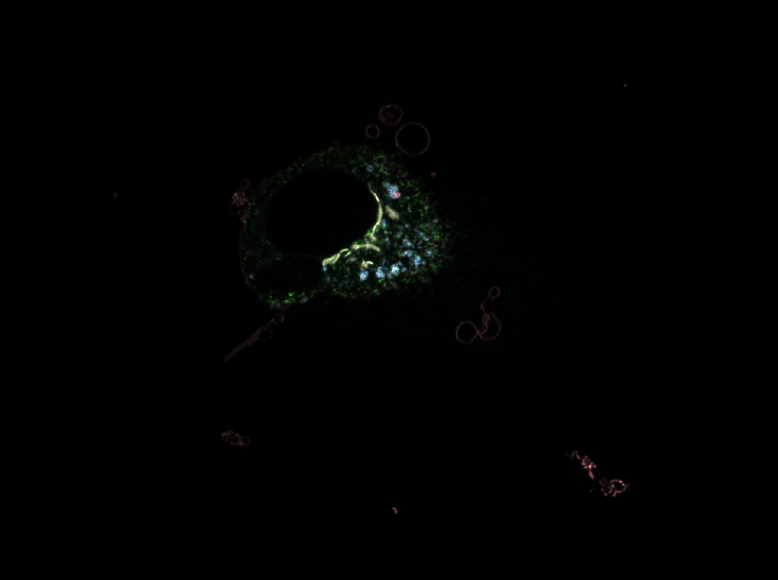

In [5]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']
file_name = str(meta_dict['file_name']).split("\\")[-1]

print("Metadata information")
print(f"File path: {file_path}")
print(f"File name: {file_name}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
for i in list(range(len(channel_names))):
    # add image to viewer
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending='additive',
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

-----
-----
# **Cellpose 3D segmentation of `Cellmask` (with optional `Nucleus`)**

This section runs a **single unified workflow** for Cellpose in true 3D:
- **cells + nuclei** (recommended when a nuclear channel is available), or
- **cells only** (PM/composite only).

Choose behavior in the next settings cell using:
- `CP_SEGMENT_NUCLEI`
- `CP_USE_NUCLEI_FOR_CELLS`

**Requirements:** Cellpose 3.x (the `cyto3` and `nuclei` models were removed in Cellpose 4). Install once with `pip install "cellpose<4"`.

**Using your own trained models:** if you fine-tuned Cellpose in [`NEW_cellpose-training.ipynb`](NEW_cellpose-training.ipynb), set `CP_CELL_MODEL_PATH` and/or `CP_NUC_MODEL_PATH` in the settings cell below to the model path printed there. The matching diameter setting is then ignored.

In [6]:
# if using a composite of organelles, specify the weights here, else leave them as 0/None
use_composite = True
invert_pm = True
PM_CH = 4
w0 = 0
w1 = 10
w2 = 10
w3 = 10
w4 = 0
w5 = 0
w6 = 0
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

In [7]:
#### USER INPUT REQUIRED ####
# Channel choices
CP_PM_CH = 4                    # channel index of the plasma membrane stain (or main cell-signal channel)
CP_NUC_CH = None                # channel index of the nuclear stain (used only when nuclei are enabled)

# Mode toggles (single unified section)
CP_SEGMENT_NUCLEI = False       # True: run nuclei model and produce nuclei labels; False: cells only
CP_USE_NUCLEI_FOR_CELLS = False # True: give nuclei channel as helper to cyto3 (only relevant if CP_SEGMENT_NUCLEI=True)

# Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE).
CP_CELL_DIAMETER = 500          # expected cell diameter (pixels in XY)
CP_NUC_DIAMETER = 200           # expected nucleus diameter (pixels in XY)

CP_XY_DOWNSAMPLE = 1            # >1 shrinks XY by this factor before Cellpose; labels are upsampled back
CP_FLOW_THRESHOLD = 0.0001      # raise to be more permissive, lower to be stricter
CP_CELLPROB_THRESHOLD = -7      # lower to segment more/larger objects
CP_MIN_SIZE_CELL = 50000        # minimum cell object size (voxels, downsampled image)
CP_MIN_SIZE_NUC = 2000          # minimum nuclei object size (voxels, downsampled image)
CP_BATCH_SIZE = 4               # lower if running out of GPU memory

# Optional: use your own fine-tuned models instead of pretrained models.
CP_CELL_MODEL_PATH = None       # None = pretrained "cyto3"
CP_NUC_MODEL_PATH = None        # None = pretrained "nuclei" (used only if CP_SEGMENT_NUCLEI=True)

# Resource profiling/logging (single-image benchmark)
CP_PROFILE_RESOURCES = True
CP_PROFILE_SAMPLE_SEC = 0.1
CP_PROFILE_LOG_DIR = out_data_path

# Log update behavior:
# Existing rows matching these key columns are replaced, so logs always reflect latest run settings.
CP_PROFILE_UPSERT_KEYS = ["dataset_id"]

In [ ]:
from importlib.metadata import version
import json
import threading
import time
from datetime import datetime

import torch
from cellpose import models
from skimage.transform import resize

if int(version('cellpose').split('.')[0]) >= 4:
    raise ImportError('Cellpose >= 4 no longer includes the cyto3/nuclei models. Run: pip install "cellpose<4" and restart the kernel.')

use_gpu = torch.cuda.is_available()
print(f'Cellpose {version("cellpose")}; using GPU: {use_gpu}')


def _prep(vol, factor):
    """rescale intensities to 0-1 and shrink XY by `factor` (ZYX in, ZYX out)"""
    vol = np.asarray(vol, dtype=np.float32)
    p1, p99 = np.percentile(vol, (1, 99.8))
    vol = np.clip((vol - p1) / (p99 - p1 + 1e-8), 0, 1)
    if factor != 1:
        vol = resize(vol, (vol.shape[0], round(vol.shape[1] / factor), round(vol.shape[2] / factor)),
                     order=1, anti_aliasing=True).astype(np.float32)
    return vol


def _restore(labels, shape):
    """upsample a label volume back to `shape` (nearest neighbour)"""
    if labels.shape != shape:
        labels = resize(labels, shape, order=0, anti_aliasing=False, preserve_range=True)
    return labels.astype(np.uint16)


def _rss_gb():
    """Return current process RSS in GiB (Linux-friendly, no extra dependency required)."""
    try:
        with open('/proc/self/status', 'r', encoding='utf-8') as f:
            for line in f:
                if line.startswith('VmRSS:'):
                    kb = float(line.split()[1])
                    return kb / (1024 ** 2)
    except Exception:
        pass
    return float('nan')


def _start_resource_monitor(enabled, gpu_enabled):
    stats = {
        "ram_gb_peak": _rss_gb(),
        "gpu_alloc_gb_peak": 0.0,
        "gpu_reserved_gb_peak": 0.0,
        "gpu_device": None,
    }

    if not enabled:
        return None, None, stats

    if gpu_enabled:
        torch.cuda.reset_peak_memory_stats()
        stats["gpu_device"] = torch.cuda.get_device_name(torch.cuda.current_device())

    stop_event = threading.Event()

    def _worker():
        while not stop_event.is_set():
            rss = _rss_gb()
            if not np.isnan(rss):
                stats["ram_gb_peak"] = max(stats["ram_gb_peak"], rss)

            if gpu_enabled:
                alloc = torch.cuda.memory_allocated() / (1024 ** 3)
                reserv = torch.cuda.memory_reserved() / (1024 ** 3)
                stats["gpu_alloc_gb_peak"] = max(stats["gpu_alloc_gb_peak"], alloc)
                stats["gpu_reserved_gb_peak"] = max(stats["gpu_reserved_gb_peak"], reserv)

            time.sleep(max(0.05, CP_PROFILE_SAMPLE_SEC))

    thread = threading.Thread(target=_worker, daemon=True)
    thread.start()
    return stop_event, thread, stats


def _stop_resource_monitor(stop_event, thread, stats, gpu_enabled):
    if stop_event is not None:
        stop_event.set()
    if thread is not None:
        thread.join(timeout=2)

    if gpu_enabled:
        stats["gpu_alloc_gb_peak"] = max(stats["gpu_alloc_gb_peak"], torch.cuda.max_memory_allocated() / (1024 ** 3))
        stats["gpu_reserved_gb_peak"] = max(stats["gpu_reserved_gb_peak"], torch.cuda.max_memory_reserved() / (1024 ** 3))


def _to_jsonable(v):
    if v is None:
        return None
    if isinstance(v, (np.integer, np.floating, np.bool_)):
        v = v.item()
    if isinstance(v, np.ndarray):
        return [_to_jsonable(x) for x in v.tolist()]
    if isinstance(v, (list, tuple)):
        return [_to_jsonable(x) for x in v]
    if isinstance(v, dict):
        return {str(k): _to_jsonable(val) for k, val in v.items()}
    try:
        if pd.isna(v):
            return None
    except Exception:
        pass
    return v


def _append_profile_record(log_dir: Path, record: dict, upsert_keys=None):
    """Upsert a profile row so repeated runs keep only the latest settings for matching keys."""
    log_dir.mkdir(parents=True, exist_ok=True)
    csv_path = log_dir / "cellpose_resource_log.csv"
    jsonl_path = log_dir / "cellpose_resource_log.jsonl"

    upsert_keys = upsert_keys or ["dataset_id"]
    new_row = pd.DataFrame([record])

    if csv_path.exists():
        existing = pd.read_csv(csv_path)
        for k in upsert_keys:
            if k not in existing.columns:
                existing[k] = None
            if k not in new_row.columns:
                new_row[k] = None

        keep_mask = np.ones(len(existing), dtype=bool)
        for k in upsert_keys:
            keep_mask &= existing[k].astype(str).values != str(new_row.iloc[0][k])

        updated = pd.concat([existing.loc[keep_mask], new_row], ignore_index=True)
    else:
        updated = new_row

    updated.to_csv(csv_path, index=False)

    with open(jsonl_path, 'w', encoding='utf-8') as f:
        for _, r in updated.iterrows():
            payload = {k: _to_jsonable(v) for k, v in r.to_dict().items()}
            f.write(json.dumps(payload) + "\n")

    print(f"Resource log updated (upsert keys={upsert_keys}):\n- {csv_path}\n- {jsonl_path}")


segment_nuclei = bool(CP_SEGMENT_NUCLEI)
use_nuc_for_cells = bool(CP_USE_NUCLEI_FOR_CELLS) and segment_nuclei
need_nuc_input = segment_nuclei or use_nuc_for_cells

if use_composite:
    pm_vol = _prep(composite, CP_XY_DOWNSAMPLE)     # ZYX
else:
    pm_vol = _prep(img_data[CP_PM_CH], CP_XY_DOWNSAMPLE)     # ZYX

nuc_vol = _prep(img_data[CP_NUC_CH], CP_XY_DOWNSAMPLE) if need_nuc_input else None
out_shape = img_data[CP_PM_CH].shape
anisotropy = scale[0] / (scale[1] * CP_XY_DOWNSAMPLE)    # Z step relative to XY pixel size

common = dict(do_3D=True, z_axis=0, anisotropy=anisotropy,
              flow_threshold=CP_FLOW_THRESHOLD, cellprob_threshold=CP_CELLPROB_THRESHOLD,
              batch_size=CP_BATCH_SIZE)

start_ts = datetime.now().isoformat(timespec='seconds')
t0 = time.perf_counter()
stop_event, monitor_thread, resource_stats = _start_resource_monitor(CP_PROFILE_RESOURCES, use_gpu)

nuc_raw = None
try:
    # optional nuclei segmentation
    if segment_nuclei:
        if CP_NUC_MODEL_PATH:
            if not Path(CP_NUC_MODEL_PATH).exists():
                raise FileNotFoundError(f'nuclei model file not found: {CP_NUC_MODEL_PATH}')
            print(f'Using custom nuclei model: {CP_NUC_MODEL_PATH}')
            nuc_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_NUC_MODEL_PATH))
        else:
            nuc_model = models.CellposeModel(gpu=use_gpu, model_type='nuclei')

        nuc_raw = nuc_model.eval(
            nuc_vol,
            diameter=None if CP_NUC_MODEL_PATH else CP_NUC_DIAMETER,
            channels=[0, 0],
            min_size=CP_MIN_SIZE_NUC,
            **common,
        )[0]

    # cell segmentation input
    if CP_CELL_MODEL_PATH:
        if not Path(CP_CELL_MODEL_PATH).exists():
            raise FileNotFoundError(f'cell model file not found: {CP_CELL_MODEL_PATH}')
        print(f'Using custom cell model: {CP_CELL_MODEL_PATH}')
        cell_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_CELL_MODEL_PATH))
    else:
        cell_model = models.CellposeModel(gpu=use_gpu, model_type='cyto3')

    if use_nuc_for_cells:
        cell_in = np.stack([pm_vol, nuc_vol], axis=-1)  # ZYXC
        cell_raw = cell_model.eval(
            cell_in,
            diameter=None if CP_CELL_MODEL_PATH else CP_CELL_DIAMETER,
            channels=[1, 2],
            channel_axis=3,
            min_size=CP_MIN_SIZE_CELL,
            **common,
        )[0]
    else:
        cell_raw = cell_model.eval(
            pm_vol,
            diameter=None if CP_CELL_MODEL_PATH else CP_CELL_DIAMETER,
            channels=[0, 0],
            min_size=CP_MIN_SIZE_CELL,
            **common,
        )[0]

finally:
    _stop_resource_monitor(stop_event, monitor_thread, resource_stats, use_gpu)

elapsed_sec = time.perf_counter() - t0

cellmask_obj = _restore(cell_raw, out_shape)

if segment_nuclei and nuc_raw is not None:
    nuc_all = _restore(nuc_raw, out_shape)
    nuc_obj = np.zeros_like(nuc_all)
    inside = (nuc_all > 0) & (cellmask_obj > 0)
    if inside.any():
        pairs, counts = np.unique(np.stack([nuc_all[inside], cellmask_obj[inside]]), axis=1, return_counts=True)
        best_cell, best_count = {}, {}
        for (n, c), k in zip(pairs.T, counts):
            if k > best_count.get(n, 0):
                best_cell[n], best_count[n] = c, k
        lut = np.zeros(int(nuc_all.max()) + 1, dtype=np.uint16)
        for n, c in best_cell.items():
            lut[n] = c
        nuc_obj = lut[nuc_all]

    print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}; nuclei found: {len(np.unique(nuc_all)) - 1}; '
          f'nuclei kept inside cells: {len(np.unique(nuc_obj)) - 1}')
else:
    nuc_all = None
    nuc_obj = None
    print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}; nuclei segmentation disabled')

print(f"Runtime: {elapsed_sec:.2f} s")
if CP_PROFILE_RESOURCES:
    print(f"Peak RAM (GiB): {resource_stats['ram_gb_peak']:.3f}")
    if use_gpu:
        print(f"Peak GPU allocated (GiB): {resource_stats['gpu_alloc_gb_peak']:.3f}")
        print(f"Peak GPU reserved (GiB): {resource_stats['gpu_reserved_gb_peak']:.3f}")

profile_record = {
    "timestamp": start_ts,
    "image_path": str(test_img_name),
    "image_name": Path(test_img_name).name,
    "dataset_id": Path(test_img_name).parent.name,
    "input_shape_zyx": list(img_data[CP_PM_CH].shape),
    "prepared_shape_zyx": list(pm_vol.shape),
    "use_composite": bool(use_composite),
    "cp_segment_nuclei": bool(segment_nuclei),
    "cp_use_nuclei_for_cells": bool(use_nuc_for_cells),
    "cp_pm_ch": int(CP_PM_CH),
    "cp_nuc_ch": int(CP_NUC_CH) if need_nuc_input else None,
    "cp_xy_downsample": int(CP_XY_DOWNSAMPLE),
    "cp_cell_diameter": float(CP_CELL_DIAMETER),
    "cp_nuc_diameter": float(CP_NUC_DIAMETER) if segment_nuclei else None,
    "cp_flow_threshold": float(CP_FLOW_THRESHOLD),
    "cp_cellprob_threshold": float(CP_CELLPROB_THRESHOLD),
    "cp_min_size_cell": int(CP_MIN_SIZE_CELL),
    "cp_min_size_nuc": int(CP_MIN_SIZE_NUC) if segment_nuclei else None,
    "cp_batch_size": int(CP_BATCH_SIZE),
    "cp_cell_model_path": str(CP_CELL_MODEL_PATH) if CP_CELL_MODEL_PATH else "cyto3",
    "cp_nuc_model_path": (str(CP_NUC_MODEL_PATH) if CP_NUC_MODEL_PATH else "nuclei") if segment_nuclei else None,
    "anisotropy": float(anisotropy),
    "runtime_sec": float(elapsed_sec),
    "cells_found": int(len(np.unique(cellmask_obj)) - 1),
    "nuclei_found": int(len(np.unique(nuc_all)) - 1) if nuc_all is not None else 0,
    "nuclei_kept_inside_cells": int(len(np.unique(nuc_obj)) - 1) if nuc_obj is not None else 0,
    "peak_ram_gib": float(resource_stats["ram_gb_peak"]),
    "peak_gpu_alloc_gib": float(resource_stats["gpu_alloc_gb_peak"]),
    "peak_gpu_reserved_gib": float(resource_stats["gpu_reserved_gb_peak"]),
    "gpu_name": resource_stats["gpu_device"],
}

if CP_PROFILE_RESOURCES:
    _append_profile_record(Path(CP_PROFILE_LOG_DIR), profile_record, upsert_keys=CP_PROFILE_UPSERT_KEYS)

if segment_nuclei:
    viewer.add_image(img_data[CP_NUC_CH], scale=scale, name='Nuclei channel', blending='additive', colormap=color_map[CP_NUC_CH])
if use_composite:
    viewer.add_image(composite, scale=scale, name='Organelle composite', blending='additive')
else:
    viewer.add_image(img_data[CP_PM_CH], scale=scale, name='Plasma membrane channel', blending='additive')
if nuc_obj is not None:
    viewer.add_labels(nuc_all, scale=scale, name='Cellpose ALL nuclei')
    viewer.add_labels(nuc_obj, scale=scale, name='Cellpose nuclei', opacity=0.5)
viewer.add_labels(cellmask_obj, scale=scale, name='Cellpose cellmask', opacity=0.5)
viewer.grid.enabled = False

Cellpose 3.1.1.3; using GPU: True


/nas/longleaf/home/srhoads/.conda/envs/cellpose/lib/python3.12/site-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


Cells found: 1; nuclei segmentation disabled
Runtime: 13.63 s
Peak RAM (GiB): 4.938
Peak GPU allocated (GiB): 1.363
Peak GPU reserved (GiB): 1.891


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [ ]:
# # Stack (nucleus, cell) as uint16 and save. stack_masks() casts to uint8, which export_tiff then
# # flattens to binary, so it is not used here: the instance labels must be preserved.
# stack = np.stack([nuc_obj, cellmask_obj], axis=0).astype(np.uint16)
# out_file_n = export_inferred_organelle(stack, 'masks_cellpose', meta_dict, out_data_path)
# print(f'saved to: {out_data_path}')

## Save dataset-specific Cellpose config

Use this section after you settle on parameters for a dataset.

It writes:
- `cellpose_config.json` (active settings)
- `cellpose_config_history/cellpose_config_YYYYMMDD_HHMMSS.json` (timestamped snapshot)

Both files are saved inside the dataset folder next to raw input images and are read by `NEW_cellpose-prep.ipynb`.

Tip: set the `SEGMENT_*_FOR_BATCH` options in the next cell explicitly so the saved config exactly matches how you want to run batch segmentation.

In [ ]:
import json
from datetime import datetime
from pathlib import Path


#### USER INPUT REQUIRED ####
# Point this to one dataset folder under /users/s/r/srhoads/MJFF_Cellpose-batch-testing/<dataset_id>
DATASET_FOLDER = Path(r"/users/s/r/srhoads/MJFF_Cellpose-batch-testing/000000")
SELECTED_BY = "srhoads"
NOTES = ""

CONFIG_FILENAME = "cellpose_config.json"
HISTORY_DIRNAME = "cellpose_config_history"
WRITE_CONFIG_HISTORY = True

# Batch-intent overrides (set explicitly for clarity)
SEGMENT_CELLS_FOR_BATCH = True
SEGMENT_NUCLEI_FOR_BATCH = None         # None = infer from CP_SEGMENT_NUCLEI / CP_NUC_CH
USE_NUCLEI_FOR_CELLS_FOR_BATCH = None   # None = infer from CP_USE_NUCLEI_FOR_CELLS


def _g(name, default=None):
    return globals().get(name, default)


def _as_optional_path(value):
    if value is None:
        return None
    value = str(value).strip()
    return value if value else None


def _nonzero_weight_dict(max_channels=10):
    out = {}
    for i in range(max_channels):
        val = _g(f"w{i}", 0)
        try:
            val = float(val)
        except Exception:
            val = 0.0
        if val > 0:
            out[i] = val
    return out


def build_cellpose_config(dataset_folder: Path) -> dict:
    dataset_folder = Path(dataset_folder)
    dataset_id = dataset_folder.name

    use_composite_now = bool(_g("use_composite", False))

    inferred_segment_nuclei = bool(_g("CP_SEGMENT_NUCLEI", _g("CP_NUC_CH") is not None))
    segment_nuclei = inferred_segment_nuclei if SEGMENT_NUCLEI_FOR_BATCH is None else bool(SEGMENT_NUCLEI_FOR_BATCH)

    inferred_use_nuc_for_cells = bool(_g("CP_USE_NUCLEI_FOR_CELLS", segment_nuclei)) and segment_nuclei
    use_nuc_for_cells = inferred_use_nuc_for_cells if USE_NUCLEI_FOR_CELLS_FOR_BATCH is None else bool(USE_NUCLEI_FOR_CELLS_FOR_BATCH)
    use_nuc_for_cells = use_nuc_for_cells and segment_nuclei

    settings = {
        "IM_TYPE": str(_g("im_type", ".czi")),
        "SEGMENT_CELLS": bool(SEGMENT_CELLS_FOR_BATCH),
        "SEGMENT_NUCLEI": bool(segment_nuclei),
        "CELL_SOURCE": "composite" if use_composite_now else "single",
        "PM_CH": int(_g("CP_PM_CH", _g("PM_CH", 0))),
        "COMPOSITE_WEIGHTS": _nonzero_weight_dict(),
        "INVERT_PM": bool(_g("invert_pm", False)),
        "NUC_CH": int(_g("CP_NUC_CH", 0)) if segment_nuclei or use_nuc_for_cells else 0,
        "USE_NUCLEI_FOR_CELLS": bool(use_nuc_for_cells),
        "XY_DOWNSAMPLE": int(_g("CP_XY_DOWNSAMPLE", 1)),
        "CELL_DIAMETER": int(_g("CP_CELL_DIAMETER", 0) or 0),
        "NUC_DIAMETER": int(_g("CP_NUC_DIAMETER", 0) or 0),
        "FLOW_THRESHOLD": float(_g("CP_FLOW_THRESHOLD", 0.4)),
        "CELLPROB_THRESHOLD": float(_g("CP_CELLPROB_THRESHOLD", 0.0)),
        "MIN_SIZE_CELL": int(_g("CP_MIN_SIZE_CELL", 0) or 0),
        "MIN_SIZE_NUC": int(_g("CP_MIN_SIZE_NUC", 0) or 0),
        "BATCH_SIZE": int(_g("CP_BATCH_SIZE", 8)),
        "USE_GPU": True,
        "CP_CELL_MODEL_PATH": _as_optional_path(_g("CP_CELL_MODEL_PATH", None)),
        "CP_NUC_MODEL_PATH": _as_optional_path(_g("CP_NUC_MODEL_PATH", None)),
        "PROFILE_UPSERT_KEYS": list(_g("CP_PROFILE_UPSERT_KEYS", ["dataset_id"])),
    }

    if settings["CELL_SOURCE"] == "single":
        settings["COMPOSITE_WEIGHTS"] = {}

    if not settings["SEGMENT_CELLS"] and not settings["SEGMENT_NUCLEI"]:
        raise ValueError("At least one of SEGMENT_CELLS_FOR_BATCH or SEGMENT_NUCLEI_FOR_BATCH must be enabled.")

    if settings["CELL_SOURCE"] == "composite" and not settings["COMPOSITE_WEIGHTS"] and settings["SEGMENT_CELLS"]:
        raise ValueError("CELL_SOURCE is 'composite' but COMPOSITE_WEIGHTS is empty. Set w0-w9 and rerun.")

    config = {
        "dataset_id": dataset_id,
        "config_version": "1.0",
        "selected_on": datetime.now().isoformat(timespec="seconds"),
        "selected_by": SELECTED_BY,
        "notes": NOTES,
        "generated_by": "NEW_infer_masks_cellpose.ipynb",
        "generation_reason": "infer-notebook-export",
        "settings": settings,
    }
    return config


DATASET_FOLDER = Path(DATASET_FOLDER)
if not DATASET_FOLDER.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_FOLDER}")

config_obj = build_cellpose_config(DATASET_FOLDER)
settings = config_obj["settings"]

history_dir = DATASET_FOLDER / HISTORY_DIRNAME
if WRITE_CONFIG_HISTORY:
    history_dir.mkdir(parents=True, exist_ok=True)

active_path = DATASET_FOLDER / CONFIG_FILENAME
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
history_path = history_dir / f"cellpose_config_{stamp}.json"

text = json.dumps(config_obj, indent=2)
active_path.write_text(text)
if WRITE_CONFIG_HISTORY:
    history_path.write_text(text)

print("Saved Cellpose dataset config")
print(f"- active:  {active_path}")
if WRITE_CONFIG_HISTORY:
    print(f"- history: {history_path}")
print("\nSummary")
print(f"dataset_id: {config_obj['dataset_id']}")
print(f"segment cells: {settings['SEGMENT_CELLS']}")
print(f"segment nuclei: {settings['SEGMENT_NUCLEI']}")
print(f"cell source: {settings['CELL_SOURCE']}")
print(f"PM_CH: {settings['PM_CH']} | NUC_CH: {settings['NUC_CH']}")
print(f"XY_DOWNSAMPLE: {settings['XY_DOWNSAMPLE']}")
print(f"use nuclei for cells: {settings['USE_NUCLEI_FOR_CELLS']}")
print(f"profile upsert keys: {settings['PROFILE_UPSERT_KEYS']}")